In [ ]:
import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS
import jax.numpy as jnp
import jax 
import arviz as az

In [ ]:
# from simulate import generate_covariance_matrix, reduce_to_accessible, sample_measurements

import jax
import jax.numpy as jnp
from jax import random
import matplotlib.pyplot as plt

def generate_covariance_matrix(r: float) -> jax.Array:
    """Returns 4x4 V(r) for the two-mode squeezed vacuum (joint state,
    both wedges). Used only for the idealized joint-access comparison —
    the physically realistic pipeline uses reduce_to_accessible(V) below."""
    cov_matrix = jnp.array([[jnp.cosh(2*r), 0, jnp.sinh(2*r), 0],
                            [0, jnp.cosh(2*r), 0, -jnp.sinh(2*r)],
                            [jnp.sinh(2*r), 0, jnp.cosh(2*r), 0],
                            [0, -jnp.sinh(2*r), 0, jnp.cosh(2*r)]])
    return cov_matrix


def reduce_to_accessible(V: jax.Array) -> jax.Array:
    """Top-left 2x2 block — the one-wedge (right-wedge) marginal state
    V_R(r) = cosh(2r) I_2, i.e. what an outside observer actually has
    access to. This is the physically realistic starting point for the
    main experiment; recovering the full joint state from this alone is
    not possible, since many joint states share the same marginal."""
    top_left_block = V[:2, :2]
    return top_left_block


def sample_measurements(V_A, n_samples, noise_level, measurement_type, key):
    """
    Simulates detector outcomes for the one-wedge accessible mode V_A (2x2).

    This is a two-step model, kept explicitly separate:
      1. State sampling: x ~ N(0, V_A) via Cholesky — samples the Gaussian
         state's Wigner function. This alone is NOT a measurement outcome.
      2. Measurement protocol: converts state samples into what a given
         detector scheme would actually report.
           - joint:     both quadratures observed exactly (idealized limit)
           - homodyne:  only one quadrature observed per shot, chosen at
                        random; the other is missing (NaN), not zero
           - heterodyne: both quadratures observed every shot, but with an
                        unavoidable +1 unit of vacuum noise added
                        (Sigma_het = V_A + I_2), per Weedbrook et al. Sec II.5
    Independent Gaussian detector noise (sigma_noise) is added on top of
    the ideal measurement outcome in all cases, to emulate real apparatus
    imperfection.

    Returns (n_samples, 2) array.
    """
    # --- Step 1: state sampling (Wigner-function sampling, not a measurement yet) ---
    state_key, choice_key, heterodyne_key, detector_key = random.split(key, 4)
    L = jnp.linalg.cholesky(V_A)  # lower triangular matrix such that V_A = L @ L.T
    z = random.normal(state_key, shape=(n_samples, 2))
    samples = z @ L.T  # samples ~ N(0, V_A)

    # --- Step 2: measurement protocol ---
    if measurement_type == 'joint':
        pass  # idealized: both quadratures observed exactly, nothing to add here
    elif measurement_type == 'homodyne':
        # each shot, randomly choose to measure x or p (local-oscillator phase
        # choice); mask the unmeasured quadrature as missing, not zero
        mask = random.randint(choice_key, shape=(n_samples,), minval=0, maxval=2)
        samples = jnp.where((mask == 0)[:, None], samples.at[:, 1].set(jnp.nan), samples)
        samples = jnp.where((mask == 1)[:, None], samples.at[:, 0].set(jnp.nan), samples)
    elif measurement_type == 'heterodyne':
        # fixed +1 unit of vacuum noise (Sigma_het = V_A + I_2), NOT scaled
        # by noise_level -- this is a fundamental measurement penalty, not
        # a technical/detector imperfection
        samples += random.normal(heterodyne_key, shape=(n_samples, 2))
    else:
        raise ValueError(f"Unknown measurement type: {measurement_type}")

    # --- detector noise, on top of the measurement outcome, all schemes ---
    detector_noise = noise_level * random.normal(detector_key, shape=(n_samples, 2))
    samples += detector_noise

    return samples


def sample_idealized_joint_access(V, n_samples, noise_level, key):
    """Idealized COMPARISON case only: samples both modes (right + left
    wedge) as if an observer had access to the full joint state. This is
    not physically realistic (the left-wedge/partner mode is inaccessible
    behind the horizon) -- it exists purely to quantify, by contrast, how
    much reconstruction accuracy is lost when restricted to one wedge.
    V must be the full 4x4 joint covariance matrix. Returns (n_samples, 4).
    """
    state_key, noise_key = random.split(key)
    L = jnp.linalg.cholesky(V)
    z = random.normal(state_key, shape=(n_samples, 4))
    samples = z @ L.T
    noise = noise_level * random.normal(noise_key, shape=(n_samples, 4))
    samples += noise
    return samples


def plot_samples(samples):
    """Plots the samples in phase space."""
    samples = jax.device_get(samples)
    plt.figure(figsize=(6, 6))
    plt.scatter(samples[:, 0], samples[:, 1], alpha=0.5, s=10)
    plt.title("Phase Space Samples")
    plt.xlabel("X Quadrature")
    plt.ylabel("P Quadrature")
    plt.axis('equal')
    plt.grid(True)
    plt.show()


def main():
    # Example usage: physically realistic one-wedge pipeline
    r = 0.5  # Squeezing parameter
    V = generate_covariance_matrix(r)
    V_A = reduce_to_accessible(V)  # one-wedge marginal, the physical case

    n_samples = 1000
    noise_level = 0.1
    key = random.key(42)

    for measurement_type in ('joint', 'homodyne', 'heterodyne'):
        key, sample_key = random.split(key)
        samples = sample_measurements(V_A, n_samples, noise_level, measurement_type, sample_key)
        print(measurement_type, samples[:5])

    # Idealized joint-access comparison (both wedges) - not the physical case
    joint_samples = sample_idealized_joint_access(V, n_samples, noise_level, key)
    print("idealized joint access:", joint_samples[:5])


if __name__ == "__main__":
    main()

joint [[-0.88648474  1.9883463 ]
 [ 0.22488755 -1.4456741 ]
 [-0.689396   -0.21046083]
 [ 0.03204393  1.9948694 ]
 [ 2.572039    1.1395311 ]]
homodyne [[        nan -1.246743  ]
 [-0.7142084          nan]
 [        nan -0.3247736 ]
 [-2.1168842          nan]
 [-0.23419307         nan]]
heterodyne [[-0.8330702   1.230174  ]
 [-0.71946293 -1.1390758 ]
 [-2.5488205  -2.9910498 ]
 [-0.7125558   1.4944117 ]
 [ 1.3100783   2.1985395 ]]
idealized joint access: [[ 0.2771423  -2.5089219  -0.8102007   2.5763688 ]
 [ 2.9359558   0.7996233   3.11169    -2.0291288 ]
 [ 1.0492843  -0.0037988   1.7839262   1.331666  ]
 [-2.2395277  -0.87337303 -2.022992    1.2307299 ]
 [-0.1271769   0.69403946  1.2418997  -1.3537734 ]]


In [ ]:
r_true = 0.5

V = generate_covariance_matrix(r_true)
V_A = reduce_to_accessible(V)

samples = sample_measurements(
    V_A,
    n_samples=1000,
    noise_level=0.1,
    measurement_type="joint",
    key=jax.random.PRNGKey(0), # or random.key(0)
)

In [ ]:
def model(X_obs):
    r = numpyro.sample("r", dist.Uniform(0, 1))
    V_est = generate_covariance_matrix(r)
    V_A_est = reduce_to_accessible(V_est) + 0.1**2 * jnp.eye(2)

    numpyro.sample("X_obs",dist.MultivariateNormal(loc=jnp.zeros(V_A_est.shape[0]), covariance_matrix=V_A_est), obs=X_obs)

In [ ]:
rng_key = jax.random.PRNGKey(0)
kernel = NUTS(model)
mcmc = MCMC(
    kernel,
    num_warmup=1000,
    num_samples=2000,
)
mcmc.run(rng_key, X_obs=samples)
posterior_samples = mcmc.get_samples()["r"]

sample: 100%|██████████| 3000/3000 [00:09<00:00, 302.53it/s, 3 steps of size 1.00e+00. acc. prob=0.94]


array([[<Axes: title={'center': 'r'}>, <Axes: title={'center': 'r'}>]],
      dtype=object)

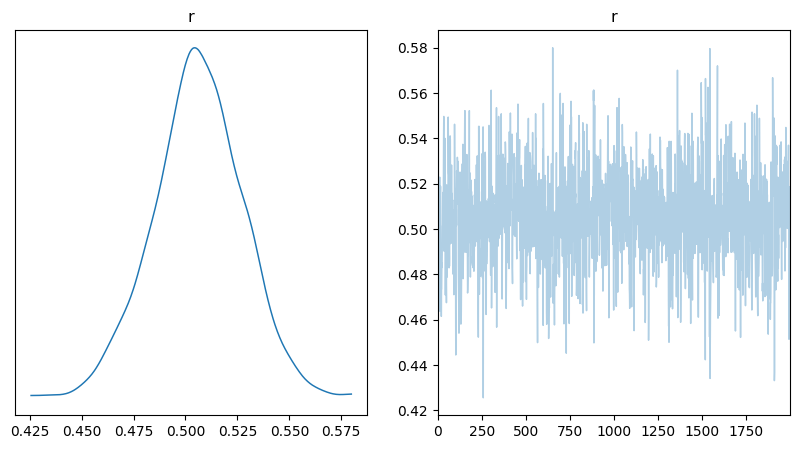

In [ ]:
data = az.from_numpyro(mcmc)
az.plot_trace(data, compact=True, figsize=(10, 5))

In [ ]:
posterior_mean = jnp.mean(posterior_samples)
posterior_mean

Array(0.5061414, dtype=float32)

***

In [ ]:
r_true = 0.5
noise_true = 1.0
n_samples = 1000

rng = jax.random.PRNGKey(0)

# Full two-mode covariance
V = generate_covariance_matrix(r_true)
V_A = reduce_to_accessible(V)

samples = sample_measurements(
    V_A,
    n_samples=1000,
    noise_level=noise_true,
    measurement_type="joint",
    key=rng, # or random.key(0)
)

In [ ]:
def model(X_obs):
    r = numpyro.sample("r", dist.Uniform(0.0, 1.0))
    noise = numpyro.sample("noise", dist.HalfNormal(1.0))

    V_est = generate_covariance_matrix(r)
    V_A_est = reduce_to_accessible(V_est) + noise**2 * jnp.eye(2)

    numpyro.sample("X_obs",dist.MultivariateNormal(loc=jnp.zeros(V_A_est.shape[0]), covariance_matrix=V_A_est), obs=X_obs)

In [ ]:
rng_key = jax.random.PRNGKey(0)
kernel = NUTS(model, target_accept_prob=0.9)
mcmc = MCMC(
    kernel,
    num_warmup=1000,
    num_samples=2000,
    num_chains=4
)
mcmc.run(rng_key, X_obs=samples)

posterior_samples = mcmc.get_samples()
r_samples = posterior_samples["r"]
noise_samples = posterior_samples["noise"]

/tmp/ipykernel_272359/1427133959.py:3: UserWarning: There are not enough devices to run parallel chains: expected 4 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(4)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  mcmc = MCMC(
sample: 100%|██████████| 3000/3000 [00:30<00:00, 96.97it/s, 39 steps of size 4.41e-02. acc. prob=0.94]  


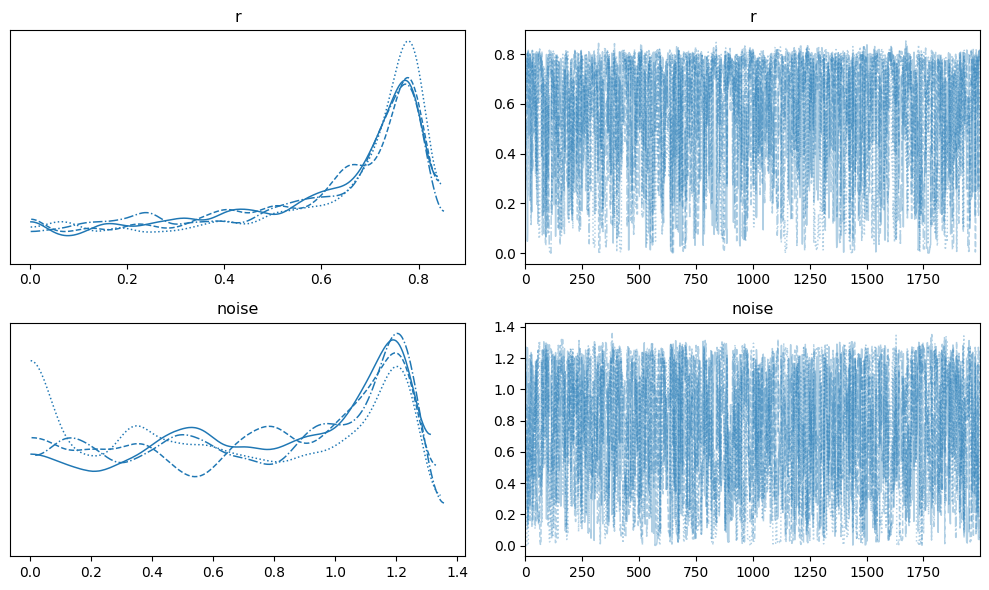

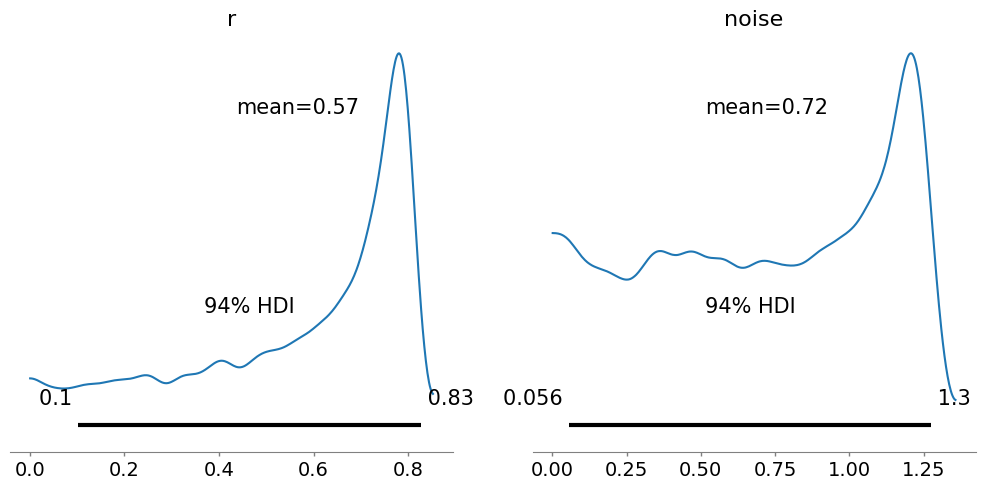

/tmp/ipykernel_272359/3849214539.py:49: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


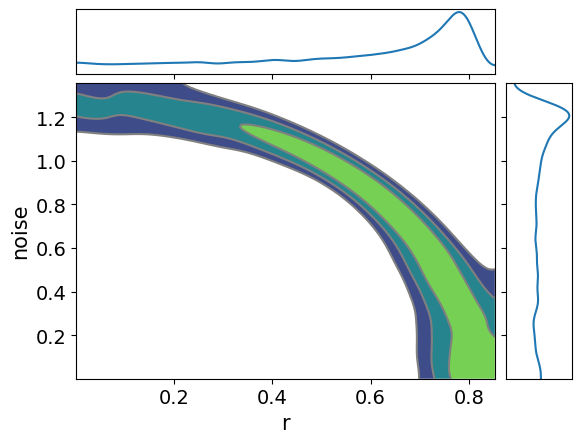

In [ ]:
data = az.from_numpyro(mcmc)

az.plot_trace(
    data,
    var_names=["r", "noise"],
    compact=True,
    figsize=(10, 6)
)

plt.tight_layout()
plt.show()


az.plot_posterior(
    data,
    var_names=["r", "noise"],
    ref_val=None,
    figsize=(10, 5)
)

plt.tight_layout()
plt.show()


az.plot_pair(
    data,
    var_names=["r", "noise"],
    kind="kde",
    marginals=True
)

plt.tight_layout()
plt.show()


In [ ]:
summary = az.summary(
    data,
    var_names=["r", "noise"],
    hdi_prob=0.90
)

print(summary)

        mean     sd  hdi_5%  hdi_95%  mcse_mean  mcse_sd  ess_bulk  ess_tail  \
r      0.567  0.233   0.167    0.820      0.007    0.004     986.0    1173.0   
noise  0.721  0.395   0.116    1.275      0.013    0.005     955.0     937.0   

       r_hat  
r        1.0  
noise    1.0  


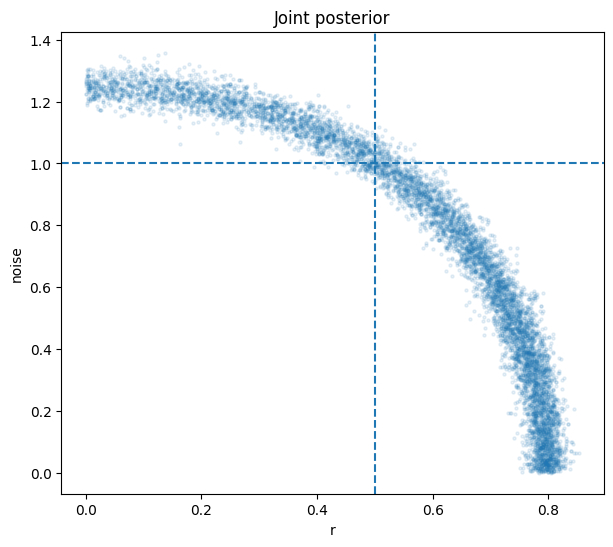

In [ ]:
plt.figure(figsize=(7, 6))

plt.scatter(
    jnp.array(posterior_samples["r"]),
    jnp.array(posterior_samples["noise"]),
    alpha=0.1,
    s=5
)

plt.axvline(r_true, linestyle="--")
plt.axhline(noise_true, linestyle="--")

plt.xlabel("r")
plt.ylabel("noise")
plt.title("Joint posterior")

plt.show()

In [ ]:
posterior_samples = mcmc.get_samples()

r_samples = posterior_samples["r"]
noise_samples = posterior_samples["noise"]

total_variance = (
    jnp.cosh(2 * r_samples)
    + noise_samples**2
)

print("Posterior mean total variance:",
      float(jnp.mean(total_variance)))

print("True total variance:",
      float(jnp.cosh(2 * r_true) + noise_true**2))

Posterior mean total variance: 2.5636725425720215
True total variance: 2.5430805683135986


When both the squeezing parameter (r) and detector noise ($\sigma$) are treated as unknown, Bayesian inference successfully recovers the total observed variance. However, (r) and ($\sigma$) are only weakly identifiable individually because both parameters contribute to the same isotropic variance term

***
## Using updated measurement functions with detector noise

In [7]:
import numpy as np
import jax
import jax.numpy as jnp
from jax import random

import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS

import arviz as az
import matplotlib.pyplot as plt

In [11]:
from simulate import sample_measurements, generate_covariance_matrix, sample_calibration, reduce_to_accessible

In [12]:
r_true = 0.5
noise_true = 1.0
n_samples = 1000
n_calibration = 1000
seed = 0
key_signal, key_cal = random.split(random.key(seed))
# Accessible one-mode covariance
V = generate_covariance_matrix(r_true)
V_A = reduce_to_accessible(V)

print("True r:", r_true)
print("True detector noise:", noise_true)
print("Accessible covariance:\n", V_A)

measurement_types = ["joint", "homodyne", "heterodyne"]

datasets = {}

for i, mt in enumerate(measurement_types):

    # Independent keys for every signal/calibration run
    key_signal_i, key_cal_i = random.split(
        random.fold_in(key_signal, i)
    )

    # Signal data: state + measurement effects + detector noise
    X_obs = sample_measurements(
        V_A,
        n_samples=n_samples,
        noise_level=noise_true,
        measurement_type=mt,
        key=key_signal_i,
    )

    # Vacuum calibration: no unknown squeezing signal
    calibration_data = sample_calibration(
        n_calibration=n_calibration,
        noise_level=noise_true,
        measurement_type=mt,
        key=key_cal_i,
        source="vacuum",
    )

    datasets[mt] = {
        "X_obs": X_obs,
        "calibration_data": calibration_data,
    }

    print(f"\n{mt}")
    print("Signal shape:", X_obs.shape)
    print("Calibration shape:", calibration_data.shape)
    print("Missing signal entries:", int(jnp.isnan(X_obs).sum()))
    print("Missing calibration entries:",
          int(jnp.isnan(calibration_data).sum()))

True r: 0.5
True detector noise: 1.0
Accessible covariance:
 [[1.5430806 0.       ]
 [0.        1.5430806]]

joint
Signal shape: (1000, 2)
Calibration shape: (1000, 2)
Missing signal entries: 0
Missing calibration entries: 0

homodyne
Signal shape: (1000, 2)
Calibration shape: (1000, 2)
Missing signal entries: 1000
Missing calibration entries: 1000

heterodyne
Signal shape: (1000, 2)
Calibration shape: (1000, 2)
Missing signal entries: 0
Missing calibration entries: 0


In [13]:
def make_model(measurement_type):

    mt = measurement_type

    def model(X_obs, calibration_data):
        r = numpyro.sample("r", dist.Uniform(0.0, 1.0))
        noise = numpyro.sample("noise", dist.HalfNormal(1.0))

        V_est = generate_covariance_matrix(r)
        V_A_est = reduce_to_accessible(V_est)

        state_variance = V_A_est[0, 0]

        # Heterodyne has one extra unit of measurement noise
        measurement_offset = 1.0 if mt == "heterodyne" else 0.0

        signal_variance = (state_variance + measurement_offset + noise**2)
        signal_dist = dist.Normal(loc=0.0, scale=jnp.sqrt(signal_variance))

        # Signal likelihood, masking unmeasured homodyne data
        signal_mask = jnp.isfinite(X_obs)
        # Replace NaNs before evaluating the log density.
        # Masked entries contribute zero to the log likelihood.
        safe_X = jnp.where(signal_mask, X_obs, 0.0)

        signal_log_prob = signal_dist.log_prob(safe_X)
        signal_log_prob = jnp.where(signal_mask, signal_log_prob, 0.0)

        numpyro.factor("signal_likelihood", jnp.sum(signal_log_prob))

        # Vacuum calibration likelihood
        # Vacuum state variance is 1 per quadrature.
        # Heterodyne adds another unit of measurement noise.
        calibration_offset = 2.0 if mt == "heterodyne" else 1.0
        calibration_variance = calibration_offset + noise**2

        calibration_dist = dist.Normal(loc=0.0, scale=jnp.sqrt(calibration_variance))
        calibration_mask = jnp.isfinite(calibration_data)
        safe_calibration = jnp.where(calibration_mask, calibration_data, 0.0)
        calibration_log_prob = calibration_dist.log_prob(safe_calibration)

        calibration_log_prob = jnp.where(calibration_mask, calibration_log_prob, 0.0)

        numpyro.factor(
            "calibration_likelihood",
            jnp.sum(calibration_log_prob)
        )

    return model

In [14]:
results = {}

for i, mt in enumerate(measurement_types):

    print(f"\n{'=' * 55}")
    print(f"Running inference: {mt}")
    print(f"{'=' * 55}")

    model_mt = make_model(mt)

    kernel = NUTS(
        model_mt,
        target_accept_prob=0.9
    )

    mcmc = MCMC(
        kernel,
        num_warmup=1000,
        num_samples=2000,
        num_chains=4,
        progress_bar=True,
    )

    run_key = random.fold_in(random.key(100), i)

    mcmc.run(
        run_key,
        X_obs=datasets[mt]["X_obs"],
        calibration_data=datasets[mt]["calibration_data"],
    )

    results[mt] = mcmc

    # Diagnostics
    idata = az.from_numpyro(mcmc)

    print(f"\nPosterior summary: {mt}")

    print(
        az.summary(
            idata,
            var_names=["r", "noise"],
            hdi_prob=0.90,
        )
    )


Running inference: joint


/tmp/ipykernel_689961/1499975666.py:16: UserWarning: There are not enough devices to run parallel chains: expected 4 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(4)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  mcmc = MCMC(
sample: 100%|██████████| 3000/3000 [00:02<00:00, 1173.91it/s, 3 steps of size 3.26e-01. acc. prob=0.95] 
/tmp/ipykernel_689961/1499975666.py:16: UserWarning: There are not enough devices to run parallel chains: expected 4 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(4)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  mcmc = MCMC(



Posterior summary: joint
        mean     sd  hdi_5%  hdi_95%  mcse_mean  mcse_sd  ess_bulk  ess_tail  \
r      0.452  0.051   0.369    0.534      0.001    0.001    3219.0    3655.0   
noise  1.006  0.032   0.952    1.057      0.001    0.000    2812.0    2730.0   

       r_hat  
r        1.0  
noise    1.0  

Running inference: homodyne


sample: 100%|██████████| 3000/3000 [00:02<00:00, 1149.16it/s, 3 steps of size 4.80e-01. acc. prob=0.95] 
/tmp/ipykernel_689961/1499975666.py:16: UserWarning: There are not enough devices to run parallel chains: expected 4 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(4)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  mcmc = MCMC(



Posterior summary: homodyne
        mean     sd  hdi_5%  hdi_95%  mcse_mean  mcse_sd  ess_bulk  ess_tail  \
r      0.538  0.056   0.452    0.634      0.001    0.001    3524.0    3878.0   
noise  0.950  0.046   0.872    1.022      0.001    0.001    3165.0    3441.0   

       r_hat  
r        1.0  
noise    1.0  

Running inference: heterodyne


sample: 100%|██████████| 3000/3000 [00:02<00:00, 1191.41it/s, 7 steps of size 4.69e-01. acc. prob=0.96] 



Posterior summary: heterodyne
        mean     sd  hdi_5%  hdi_95%  mcse_mean  mcse_sd  ess_bulk  ess_tail  \
r      0.535  0.060   0.436    0.627      0.001    0.001    3127.0    3170.0   
noise  0.977  0.048   0.900    1.057      0.001    0.001    2944.0    3160.0   

       r_hat  
r        1.0  
noise    1.0  


In [ ]:
summary_rows = []

for mt, mcmc in results.items():

    posterior = mcmc.get_samples()

    r_samples = np.asarray(posterior["r"])
    noise_samples = np.asarray(posterior["noise"])

    r_ci = np.percentile(r_samples, [5, 95])
    noise_ci = np.percentile(noise_samples, [5, 95])

    summary_rows.append({
        "measurement": mt,
        "r_mean": r_samples.mean(),
        "r_sd": r_samples.std(),
        "r_90%_low": r_ci[0],
        "r_90%_high": r_ci[1],
        "noise_mean": noise_samples.mean(),
        "noise_sd": noise_samples.std(),
        "noise_90%_low": noise_ci[0],
        "noise_90%_high": noise_ci[1],
    })

import pandas as pd

summary_df = pd.DataFrame(summary_rows)

print("\nTrue r:", r_true)
print("True noise:", noise_true)

print("\nComparison of measurement schemes:")
print(summary_df.round(3).to_string(index=False))


True r: 0.5
True noise: 1.0

Comparison of measurement schemes:
measurement  r_mean  r_sd  r_90%_low  r_90%_high  noise_mean  noise_sd  noise_90%_low  noise_90%_high
      joint   0.452 0.051      0.364       0.530       1.006     0.032          0.953           1.059
   homodyne   0.538 0.056      0.442       0.626       0.950     0.046          0.875           1.026
 heterodyne   0.535 0.060      0.432       0.625       0.977     0.048          0.896           1.055


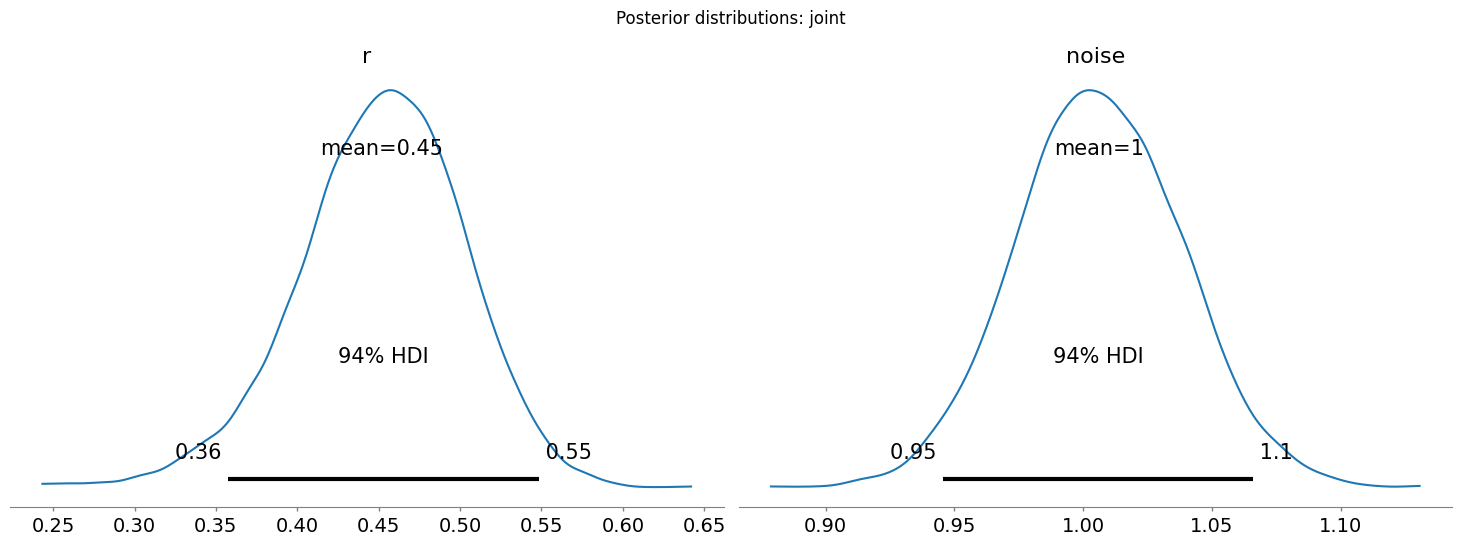

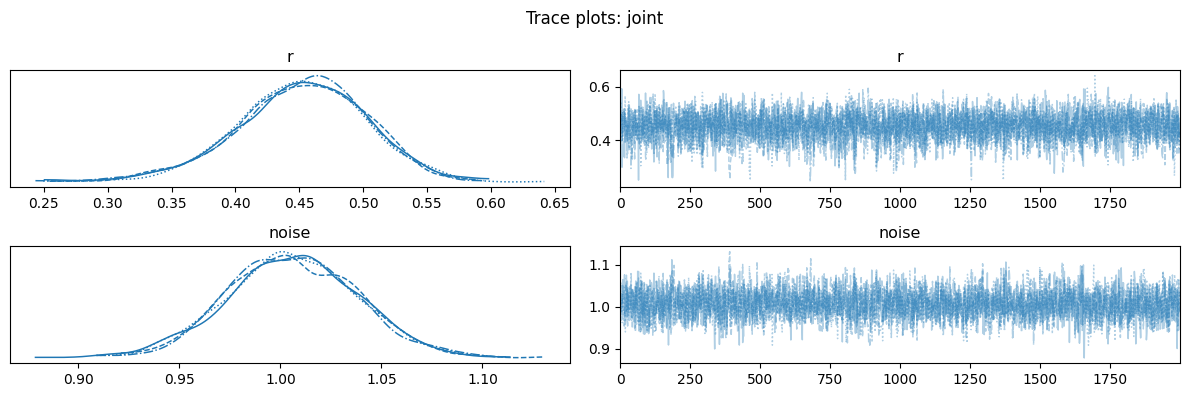

/tmp/ipykernel_689961/2285571361.py:40: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


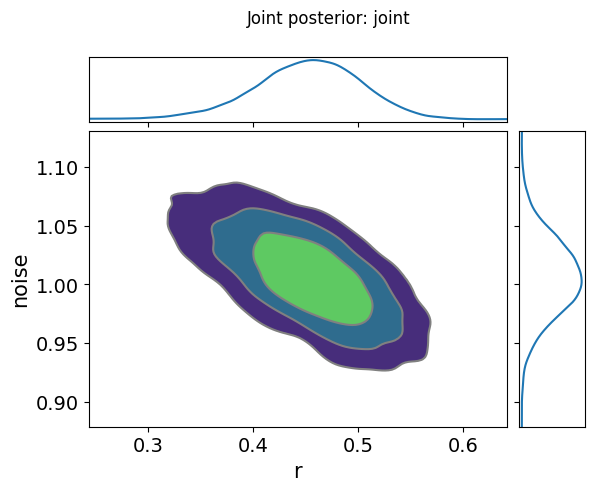

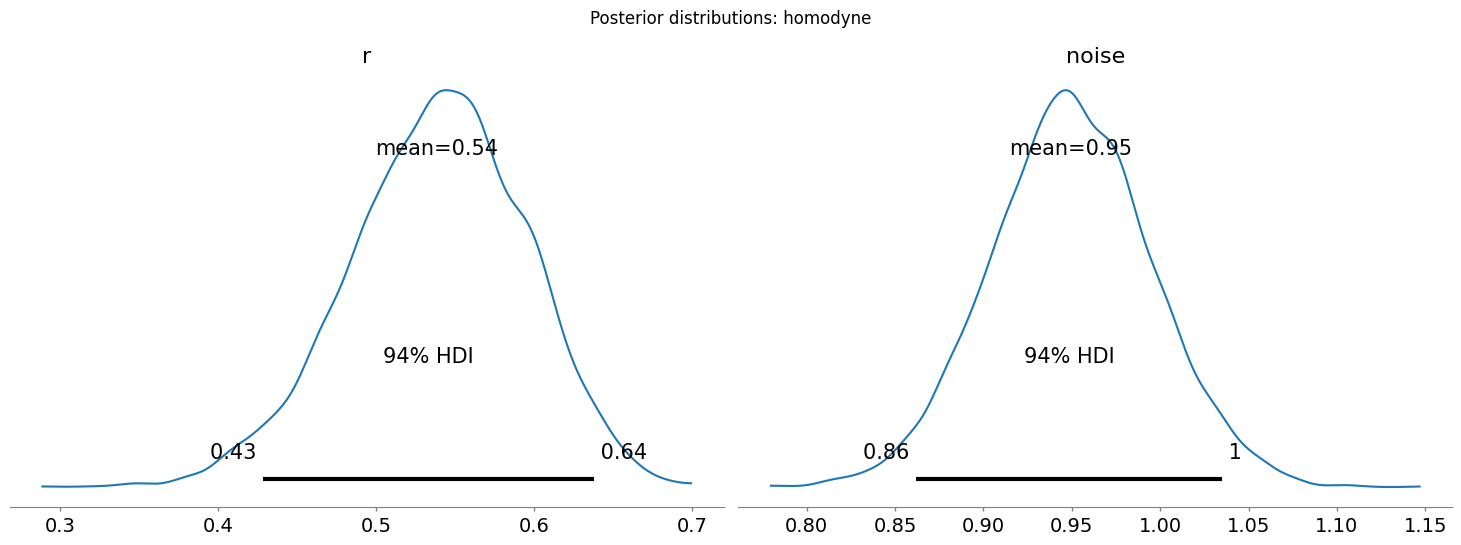

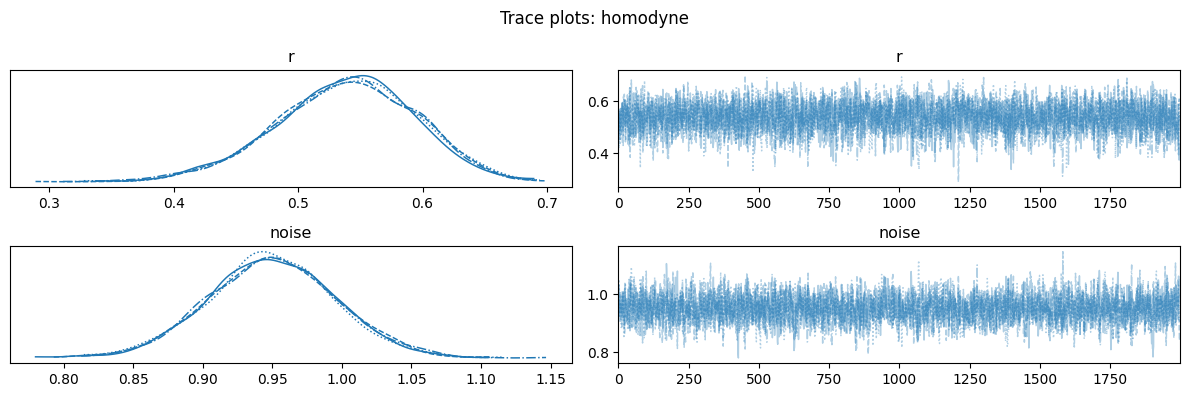

/tmp/ipykernel_689961/2285571361.py:40: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


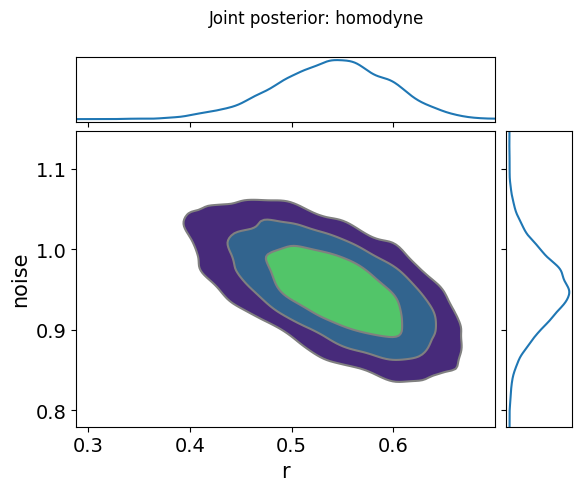

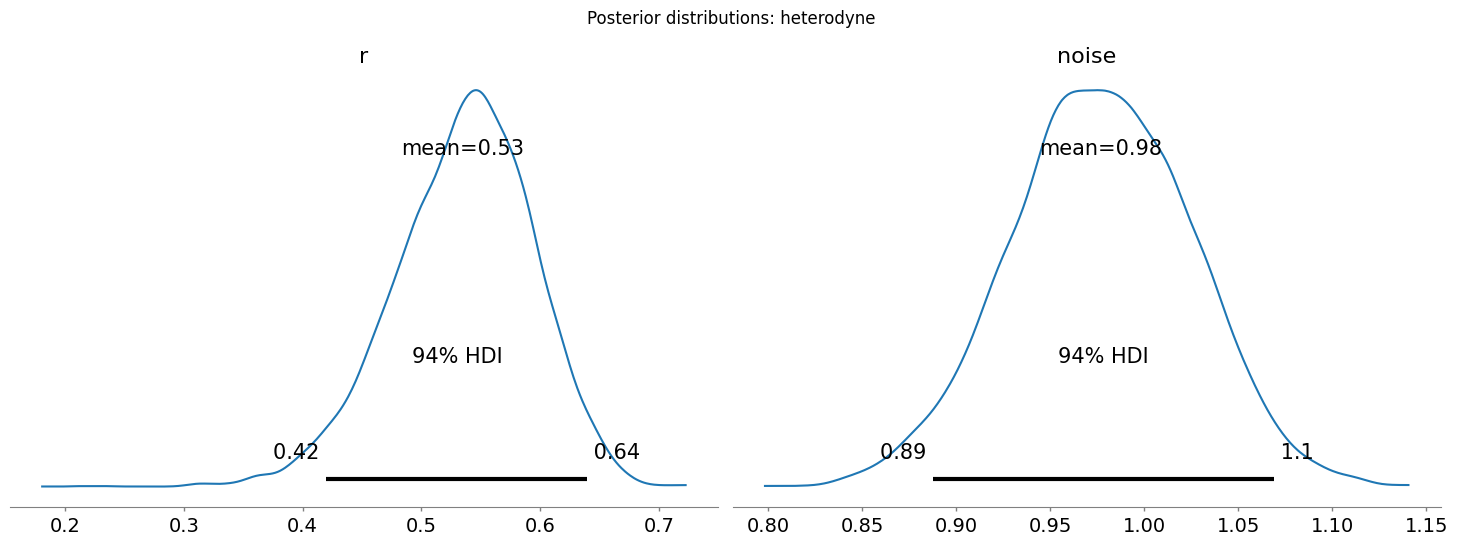

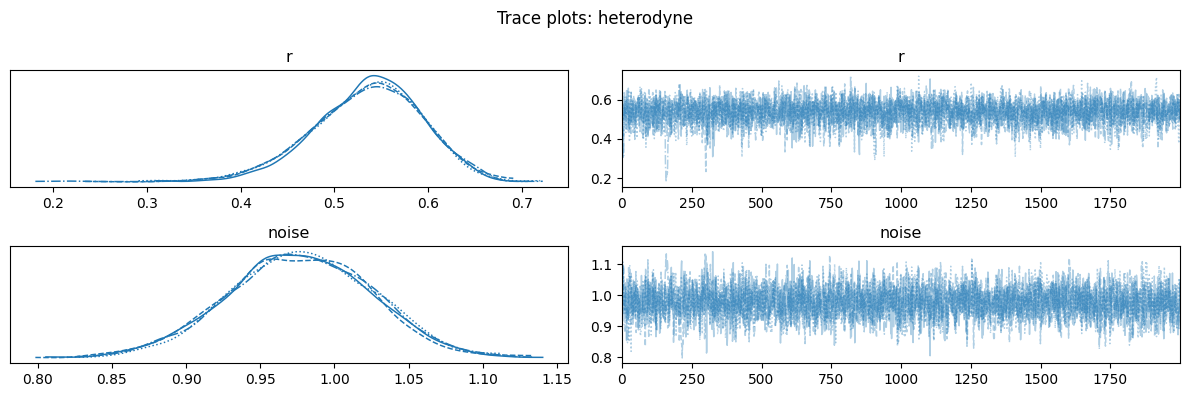

/tmp/ipykernel_689961/2285571361.py:40: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


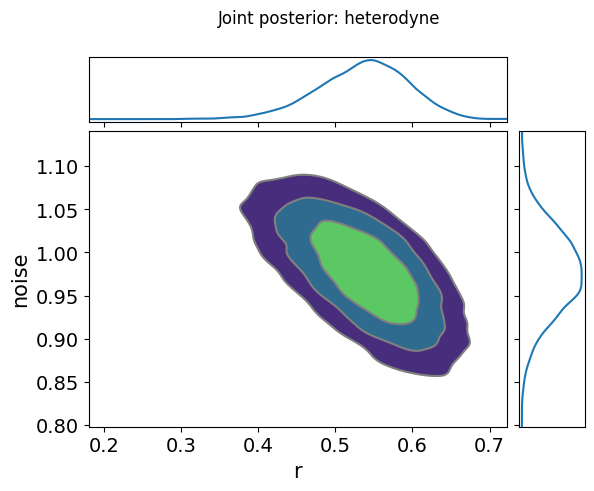

In [ ]:
for mt, mcmc in results.items():

    idata = az.from_numpyro(mcmc)

    # Marginal posterior distributions
    az.plot_posterior(
        idata,
        var_names=["r", "noise"],
        ref_val=None,
    )

    plt.suptitle(f"Posterior distributions: {mt}")
    plt.tight_layout()
    plt.show()

    # Trace plots
    az.plot_trace(
        idata,
        var_names=["r", "noise"],
        compact=True,
    )

    plt.suptitle(f"Trace plots: {mt}")
    plt.tight_layout()
    plt.show()

    # Joint posterior: trade-off between r and noise
    az.plot_pair(
        idata,
        var_names=["r", "noise"],
        kind="kde",
        marginals=True,
    )

    plt.suptitle(f"Joint posterior: {mt}")
    plt.tight_layout()
    plt.show()